# Split 70:30 
# Train with RFC and analyse performance
# Compare performance against a two models: 
#    - one that guesses randomly 
#    - another that always return "No".
# Hyperparameter Tuning ?? 5-fold cross-validation.


In [1]:
import os
import re
import random
import joblib
import json

import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    precision_recall_curve, average_precision_score
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

import matplotlib.pyplot as plt
import seaborn as sns


## 1. Load the dataset

In [2]:
path = Path.cwd()
data_path = path.parent / "data"
model_path = path.parent / "models"

# Input: featurised 
input_path = data_path / "csic_2010_featurised.parquet" 

# Output: model
output_path = model_path / "model.joblib" 

In [3]:
# Load the featurised dataset
%time
df_featurised = pd.read_parquet(input_path)

CPU times: user 10 μs, sys: 1e+03 ns, total: 11 μs
Wall time: 28.8 μs


In [4]:
df_featurised.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61065 entries, 0 to 61064
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   contentLength                  61065 non-null  float64
 1   method_GET                     61065 non-null  float64
 2   method_POST                    61065 non-null  float64
 3   method_PUT                     61065 non-null  float64
 4   host_localhost:8080            61065 non-null  float64
 5   host_localhost:9090            61065 non-null  float64
 6   url_has_select                 61065 non-null  int64  
 7   url_has_drop                   61065 non-null  int64  
 8   url_has_numeric_id             61065 non-null  int64  
 9   url_length                     61065 non-null  int64  
 10  payload_quote_count            61065 non-null  int64  
 11  payload_paren_count            61065 non-null  int64  
 12  payload_slash_count            61065 non-null 

## 2. Split data into train/test

Identiy Training Input and Target Columns

In [5]:
#numeric_cols = df_featurised.select_dtypes(include=np.number).columns.tolist()
train_cols = list(df_featurised.columns)[0:-1]
print(train_cols)

['contentLength', 'method_GET', 'method_POST', 'method_PUT', 'host_localhost:8080', 'host_localhost:9090', 'url_has_select', 'url_has_drop', 'url_has_numeric_id', 'url_length', 'payload_quote_count', 'payload_paren_count', 'payload_slash_count', 'payload_parameter_count', 'payload_percent_count', 'payload_percent_encoded_count', 'payload_length', 'is_17_to_32_bytes', 'is_empty_payload']


In [6]:
#print(len(numeric_cols))
#print(numeric_cols)
# All columns except the last one (`anomalous` which is the target column) are training columns 
#train_cols = numeric_cols[0:-1]
# print(len(train_cols))
#print(train_cols)
# The Last column `anomalous` is the target column
#target_col = numeric_cols[-1]
target_col = 'anomalous' 
#print(len(target_col))
print(target_col)

anomalous


Using the Train and Target columns prepare training and target dataset

In [7]:
# Train dataset
df_train = df_featurised[train_cols]
df_train

,contentLength,method_GET,method_POST,method_PUT,host_localhost:8080,host_localhost:9090,url_has_select,url_has_drop,url_has_numeric_id,url_length,payload_quote_count,payload_paren_count,payload_slash_count,payload_parameter_count,payload_percent_count,payload_percent_encoded_count,payload_length,is_17_to_32_bytes,is_empty_payload
0,0.0,1.0,0.0,0.0,1.0,0.0,0,0,0,44,0,0,0,0,0,0,0,0,1
1,0.0,1.0,0.0,0.0,1.0,0.0,0,0,0,70,0,0,0,0,0,0,0,0,1
2,0.0,1.0,0.0,0.0,1.0,0.0,0,0,0,57,0,0,0,1,0,0,4,0,1
3,0.0,1.0,0.0,0.0,1.0,0.0,0,0,0,48,0,0,0,1,4,4,77,0,1
4,174.0,0.0,1.0,0.0,1.0,0.0,0,0,0,57,2,0,5,1,18,18,174,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61060,33.0,0.0,1.0,0.0,1.0,0.0,0,0,0,48,0,0,0,1,0,0,33,0,0
61061,248.0,0.0,1.0,0.0,1.0,0.0,0,0,0,49,0,0,0,1,3,3,248,0,0
61062,0.0,1.0,0.0,0.0,1.0,0.0,0,0,0,52,0,0,0,1,0,0,58,0,1
61063,38.0,0.0,1.0,0.0,1.0,0.0,0,0,0,47,0,0,0,1,0,0,38,0,0


In [8]:
# Target dataset
df_target = df_featurised[target_col]
df_target

0        0
1        1
2        0
3        1
4        1
        ..
61060    0
61061    1
61062    1
61063    0
61064    0
Name: anomalous, Length: 61065, dtype: int64

Split the training and targets in 70:30 ratio (70% for training and 30% for testing)

In [9]:
# Use train_test_split with stratification
test_size = 0.3 # 70:30 
random_state = 42 # Const seed
input_train, input_test, output_train, output_test = train_test_split(
    df_train, # X
    df_target, # y
    test_size=test_size,
    stratify=df_target, # y
    random_state=random_state,
)

> `test_size=0.3` implies `30%` of the dataset for testing, leaving `70%` for training.  
> The dataset is imbalanced, `stratify` ensures that the split maintains the same proportion of classes (`anom` / `norm`) as in the full dataset.  
> `input_train` and `output_train` represent the resulting **70% training and target feature data subset** respectively  
> `input_test` and `output_test` represent the resulting **30% testing and target feature data subset** respectively  


In [10]:
print(f"input_train: {input_train.shape}")
print(f"output_train: {input_train.shape}")

input_train: (42745, 19)
output_train: (42745, 19)


In [11]:
print(f"input_test: {input_test.shape}")
print(f"output_test: {input_test.shape}")

input_test: (18320, 19)
output_test: (18320, 19)


## 3. Train baseline model

Use `RandomForestClassifier` with default hyperparameters

In [12]:
model = RandomForestClassifier(random_state=42)

Use training and target data subset for model training

In [13]:
model.fit(input_train, output_train.values.ravel())

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Check the feature importance

In [14]:
# Sort features by importance (descending order)
sorted_indices = model.feature_importances_.argsort()[::-1]  # [::-1] reverses the order to get descending
sorted_features = [train_cols[i] for i in sorted_indices]
sorted_importances = model.feature_importances_[sorted_indices]

print("Feature Importances (Sorted):")
for feature, importance in zip(sorted_features, sorted_importances):
    print(f"    {feature}: {importance:.4f}")

Feature Importances (Sorted):
    payload_length: 0.2857
    url_length: 0.2749
    payload_percent_count: 0.1135
    payload_percent_encoded_count: 0.0994
    contentLength: 0.0794
    url_has_numeric_id: 0.0362
    payload_quote_count: 0.0327
    payload_parameter_count: 0.0297
    payload_slash_count: 0.0188
    method_PUT: 0.0046
    payload_paren_count: 0.0041
    host_localhost:9090: 0.0038
    host_localhost:8080: 0.0037
    is_17_to_32_bytes: 0.0035
    method_GET: 0.0034
    method_POST: 0.0032
    is_empty_payload: 0.0025
    url_has_select: 0.0006
    url_has_drop: 0.0003


**Observations:**  
- Features with high imortance  (Importance >= 0.05): `payload_length(`, `url_length`, `payload_percent_count`, `payload_percent_encoded_count`, `contentLength`
- Features with moderate importance (0.01 <= Importance < 0.05): `url_has_numeric_id`, `payload_quote_count`, `payload_parameter_count`, `payload_slash_count`
- Features with low importance (Importance < 0.01): `method_PUT`, `payload_paren_count`, `host_localhost:9090`, `host_localhost:8080`, `is_17_to_32_bytes`, `method_GET`, `method_POST`, `is_empty_payload`, `url_has_select`, `url_has_drop`

**Enhancement:** Focus on the most predictive features to improve model efficiency and performance.

In [15]:
# Save the model
#joblib.dump(model, output_path)
#print(f"model_saved={model_path}")

Make predictions on the input `test` data subset

In [16]:
# Predictions
preds = model.predict(input_test)

# Prediction probabilities 
proba = model.predict_proba(input_test)[:, 1]

Evaluate model performance by comparing model predictions against the actual targets from the output `test` data subset

In [17]:
# Compute metrics
accuracy = round(float(accuracy_score(output_test, preds)), 6)
precision = round(float(precision_score(output_test, preds, zero_division=0)), 6)
recall = round(float(recall_score(output_test, preds, zero_division=0)), 6)
f1 = round(float(f1_score(output_test, preds, zero_division=0)), 6)
roc_auc = round(float(roc_auc_score(output_test, proba)), 6)
average_precision = round(float(average_precision_score(output_test, proba)), 6)

# CM w/ Normalized values
cm = confusion_matrix(output_test, preds, normalize='true'),
# CM w/ absolute values
tn, fp, fn, tp = confusion_matrix(output_test, preds).ravel()
fpr = round(fp / (fp + tn), 6)  # False Positive Rate
fnr = round(fn / (fn + tp), 6)  # False Negative Rate

# Classification report
cr = classification_report(output_test, preds, zero_division=0),

# Class (norm/anom) imbalance ratio
class_counts = Counter(output_test)
class_imbalance_ratio = round(class_counts[0] / class_counts[1], 2),  

# Test Samples
n_test = int(len(input_test))

#precision, recall, _ = precision_recall_curve(output_test, proba)

metrics = {
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "roc_auc": roc_auc,
    "average_precision": average_precision,
    "class_imbalance_ratio": class_imbalance_ratio,
    "num_test_samples": n_test,
}

print("Metrics Report:")
print(json.dumps(metrics, indent=2))
# print("")
#print("Confusion Matrix:")
#print(metrics["confusion_matrix"])
#print("Classification Report:")
#print(metrics["classification_report"])

Metrics Report:
{
  "accuracy": 0.883352,
  "precision": 0.898092,
  "recall": 0.807447,
  "f1": 0.850361,
  "roc_auc": 0.951669,
  "average_precision": 0.946433,
  "class_imbalance_ratio": [
    1.44
  ],
  "num_test_samples": 18320
}


**Observations:**  
- Accuracy `88.34%`, F1-Score: `85.04%`, and ROC-AUC: `95.17%` indicate the model performs well in classifying anomalies
- Precision `89.81%` and Average Precision: `94.64%`: High reliability in positive predictions (low false positives)
- Recall `80.74%`: Model captures most anomalies
- class_imbalance_ratio `1.44`: Indicates class imbalance i.e. ratio of norm/anom in the test targets
- `~19.26%` chance of false negatives. Further tuning hyperparameters, feature engineering, resampling may enhance recall. (Future Enhancement)

 Visualize the breakdown of correctly and incorrectly classified inputs using a confusion matrix

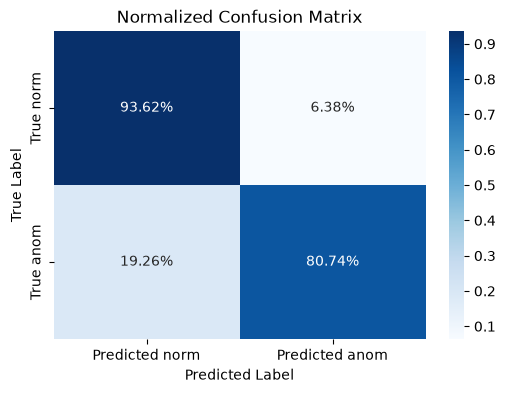

In [18]:
# Normalized confusion matrix
cm_normalized = confusion_matrix(output_test, preds, normalize='true')

# Plot
plt.figure(figsize=(6, 4))
sns.heatmap(cm_normalized, annot=True, fmt=".2%", cmap="Blues",
            xticklabels=["Predicted norm", "Predicted anom"],
            yticklabels=["True norm", "True anom"])
plt.title("Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
#plt.savefig('normalized_confusion_matrix.png', format='PNG', dpi=200, bbox_inches='tight')
plt.show()

**Observations:**  
- `93.62%` of `true norm` instances **correctly** predicted as `norm` (True Negatives, TN).
- `6.38%` of `true norm` instances were **incorrectly** predicted as `anom` (False Positives, FP).
- `19.26%` of `true anom` instances were **incorrectly** predicted as `norm` (False Negatives, FN).
- `80.74%` of `true anom` instances were **correctly** predicted as `anom` (True Positives, TP).

**Conclusion:**  
- The model is highly accurate at identifying **normal** instances, with only 6.38% false positives.
- The model correctly identifies `80.74%` of **anomalies** but misses `~19.26%` of **anomalies** (false negatives)

In [19]:
# Classification report - Precision and recall scores per class  
cr = classification_report(output_test, preds, zero_division=0)
print(cr)

              precision    recall  f1-score   support

           0       0.87      0.94      0.90     10800
           1       0.90      0.81      0.85      7520

    accuracy                           0.88     18320
   macro avg       0.89      0.87      0.88     18320
weighted avg       0.88      0.88      0.88     18320



*To improve Recall for `anom` (Reduce False Negatives), use class_weight="balanced" in RandomForestClassifier to give more weight to the minority class (anom).*

**Observations:**  

**Class 0 (`norm` instances):**  
    - **Precision (0.87):** When the model predicts `norm`, it is correct `87%` of the time viz. `13%` of `norm` instances are misclassified as `anom` *(false positives)*  
    - **Recall(0.94):**  The model correctly identifies `94%` of all true `norm` instances. Only `6%` of `norm` instances are missed *(false negatives)*
    - **f1-score (0.90):** Harmonic mean of precision and recall for `norm` is `0.90`, indicating strong performance.

**Class 1 (`anom` instances):**  
    - **Precision (0.90):** When the model predicts `anom`, it is correct `90%` of the time viz. `10%` of `anom` instances are misclassified as `norm` *(false positives)*  
    - **Recall(0.81):**  The model correctly identifies `81%` of all true `anom` instances. `19%` of `anom` instances are missed *(false negatives)*    
    - **f1-score (0.85):** Harmonic mean of precision and recall for `anom` is `0.85`, indicating good performance.

**Overall Performance:**  
**Accuracy (0.88):** The model is correct `88%` of the time across both classes.  
**Macro Avg (precision `0.89`, Recall `0.87`, f1-score `0.88`):** Unweighted average across for both classes is consistently good for all three metrics  
**Weighted Avg (precision `0.88`, Recall `0.88`, f1-score `0.88`):** Weighted average despite class imbalance `norm: 10800` and `anom: 7250` is consistently good for all three metrics  


## 4. Baseline Model Comparisons

**4.1** Use `DummyClassifier` that always predict the **majority class**

In [20]:
# Benchmark against `DummyClassifier(strategy="most_frequent")`
dummy_clf_model = DummyClassifier(strategy="most_frequent", random_state=42)

In [21]:
dummy_clf_model.fit(input_train, output_train.values.ravel())

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.59,0.41]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](19,)","['contentLength','method_GET','method_POST',...,'payload_length', 'is_17_to_32_bytes','is_empty_payload']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,19
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


Make predictions on the `input` test data subset

In [22]:
# Prediction
test_pred_dummy = dummy_clf_model.predict(input_test)

# Prediction probabilities 
test_proba_dummy = dummy_clf_model.predict_proba(input_test)[:, 1]

In [23]:
# Compute metrics
accuracy = round(float(accuracy_score(output_test, test_pred_dummy)), 6)
precision = round(float(precision_score(output_test, test_pred_dummy, zero_division=0)), 6)
recall = round(float(recall_score(output_test, test_pred_dummy, zero_division=0)), 6)
f1 = round(float(f1_score(output_test, test_pred_dummy, zero_division=0)), 6)
roc_auc = round(float(roc_auc_score(output_test, test_proba_dummy)), 6) if len(np.unique(output_test)) > 1 else 0.5
average_precision = round(float(average_precision_score(output_test, test_proba_dummy)), 6)

metrics = {
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "roc_auc": roc_auc,
    "average_precision": average_precision,
}

print("Metrics Report - DummyClassifier (Most Frequent):")
print(json.dumps(metrics, indent=2))

Metrics Report - DummyClassifier (Most Frequent):
{
  "accuracy": 0.58952,
  "precision": 0.0,
  "recall": 0.0,
  "f1": 0.0,
  "roc_auc": 0.5,
  "average_precision": 0.41048
}


**4.2** Use constant classifiers that always predicts `norm`

<!--A **constant classifier** always predicts the same class (e.g., always `norm` or always `anom`). This is useful to see how the baseline model performs compared to always guessing the majority or minority class. -->

In [24]:
test_pred_constant_norm = [0] * len(output_test)  # 0 = norm, 1 = anom

# Compute metrics
metrics_constant_norm = {
    "accuracy": round(float(accuracy_score(output_test, test_pred_constant_norm)), 6),
    "precision": precision_score(output_test, test_pred_constant_norm, zero_division=0),
    "recall": recall_score(output_test, test_pred_constant_norm, zero_division=0),
    "f1": f1_score(output_test, test_pred_constant_norm, zero_division=0),
    "roc_auc": roc_auc_score(output_test, test_pred_constant_norm) if len(np.unique(output_test)) > 1 else 0.5,
}

print("Metrics Report - Constant Classifier (Always predict `norm`):")
print(json.dumps(metrics_constant_norm, indent=2))    

Metrics Report - Constant Classifier (Always predict `norm`):
{
  "accuracy": 0.58952,
  "precision": 0.0,
  "recall": 0.0,
  "f1": 0.0,
  "roc_auc": 0.5
}


**Observations:**  
DummyClassifier always predicts the majority class `norm` because it is the most frequent in the input training data. Constant classifier always predicts `norm`. That explains the identical metrics  
- Accuracy `58.95%`: Matches the class imbalance ratio `~59%` `norm`, `~41%` `anom`
- Precision/Recall/F1 (0.0): Since it never predicts `anom`
- ROC-AUC (0.5): Equivalent to random guessing
- Average Precision `41.05%`: Slightly better than random due to the class imbalance.

Thankfully, the random forest classifier model is much better than a both these baseline models!

**Conclusion:**  
Baselines confirm that random forest classifier model is learning meaningful patterns.

## 6. `GridSearchCV` - Find the best hyperparameters using cross-validation. 

In [26]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "class_weight": ["balanced", None]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1",  # Optimize for F1-score
    n_jobs=-1
)
#model.fit(input_train, output_train.values.ravel())
grid_search.fit(input_train, output_train.values.ravel())
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-Score:", grid_search.best_score_)

Best Parameters: {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_split': 10, 'n_estimators': 50}
Best CV F1-Score: 0.8632363097187511


## 7. Cross-Validation

Evaluate performance across multiple train-test splits. The dataset has class imbalance (norm/anom ratio = 1.44), so use stratified cross-validation to ensure each fold has the same class distribution as the original dataset.

In [27]:
# Define stratified 5-fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [28]:
# Perform stratified cross-validation
X = input_train
y = output_train.values.ravel()
scoring=["accuracy", "precision", "recall", "f1"]
cv_results = cross_validate(
    model, X, y,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=scoring,
    return_train_score=False
)

In [29]:
# Print results
# print(f"Mean Accuracy: {np.mean(cv_results['test_accuracy']):.4f}")
# print(f"Mean Precision: {np.mean(cv_results['test_precision']):.4f}")
# print(f"Mean Recall: {np.mean(cv_results['test_recall']):.4f}")
# print(f"Mean F1-Score: {np.mean(cv_results['test_f1']):.4f}")
print("Stratified Cross-Validation Results:")
for metric in scoring:
    mean_score = cv_results[f"test_{metric}"].mean()
    std_score = cv_results[f"test_{metric}"].std()
    print(f"  {metric}: {mean_score:.4f} (±{std_score:.4f})")


Stratified Cross-Validation Results:
  accuracy: 0.8840 (±0.0016)
  precision: 0.8946 (±0.0088)
  recall: 0.8133 (±0.0114)
  f1: 0.8519 (±0.0030)


**Observations:**  
- **accuracy: 0.8840 (±0.0016):** The model is correct `~88.4%` of the time across all folds, with very low variance `0.16%`.  
- **precision: 0.8946 (±0.0088):** When the model predicts `anom`, it is correct `~89.5%` of the time, with low variance `0.88%`.  
- **recall: 0.8133 (±0.0114):** The model catches `~81.3%` of anomalies, with low variance `1.14%`.
- **f1: 0.8519 (±0.0030):** Balanced metric is `~85.2%`, with minimal variance (0.3%).  

**Conclusion:**  
- The close alignment between Cross Validation and test set performance confirms that the model is not overfitting and generalizes well to unseen data.
- The low standard deviations in Cross Validation scores (±0.16%–1.14%) further confirm that the model’s performance is consistent across different data splits.  


## 8. Model Comparison - XGBClassifier

In [30]:
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

models = {
    #"Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss"),
    #"SVM (Calibrated)": CalibratedClassifierCV(SVC(random_state=42), ensemble=False),
    #"Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
}
scoring = ["accuracy", "precision", "recall", "f1"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X = input_train
y = output_train.values.ravel()

for name, model in models.items():
    cv_results = cross_validate(model, X, y, cv=cv, scoring=scoring)
    print(f"{name}:")
    for metric in scoring:
        mean_score = cv_results[f"test_{metric}"].mean()
        std_score = cv_results[f"test_{metric}"].std()
        print(f"    {metric}: {mean_score:.4f} (±{std_score:.4f})")
    print()

XGBoost:
    accuracy: 0.8929 (±0.0027)
    precision: 0.9149 (±0.0105)
    recall: 0.8150 (±0.0056)
    f1: 0.8620 (±0.0026)



## 8. Model Comparison - LogisticRegression

In [31]:
from sklearn.linear_model import LogisticRegression

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
}
scoring = ["accuracy", "precision", "recall", "f1"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X = input_train
y = output_train.values.ravel()

for name, model in models.items():
    cv_results = cross_validate(model, X, y, cv=cv, scoring=scoring)
    print(f"{name}:")
    for metric in scoring:
        mean_score = cv_results[f"test_{metric}"].mean()
        std_score = cv_results[f"test_{metric}"].std()
        print(f"    {metric}: {mean_score:.4f} (±{std_score:.4f})")
    print()

/home/labhost/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/labhost/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html


Logistic Regression:
    accuracy: 0.7605 (±0.0075)
    precision: 0.8362 (±0.0127)
    recall: 0.5179 (±0.0120)
    f1: 0.6396 (±0.0125)



/home/labhost/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 5. Log results

In [173]:
# Save metrics, confusion matrix, and classification report.

In [224]:
# XGBoost, Logistic Regression, or SVM.